# Exploratory Data Analysis — Predict Future Sales

**Objetivo:** entender el comportamiento de las ventas diarias de 1C Company, una de las mayores cadenas
rusas de software, videojuegos y entretenimiento, para preparar el *forecasting* de las ventas mensuales
por par tienda-producto de **noviembre de 2015**.

## Configuración inicial

### Librerías

Importación de librerías agrupadas por categoría y definición del estilo global de las gráficas.

In [1]:
# Manipulación de datos
from pathlib import Path

import numpy as np
import pandas as pd

# Gráficas
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Notebooks
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

### Parámetros y carga de datos

Rutas parametrizadas de los archivos de entrada y función de carga que valida que cada archivo exista.

In [2]:
DATA_PATH = Path("../data/raw")

FILES = {
    "sales_train": "sales_train.csv",
    "items": "items.csv",
    "item_categories": "item_categories.csv",
    "shops": "shops.csv",
    "test": "test.csv",
}


def load_csv(file_name: str, data_path: Path = DATA_PATH) -> pd.DataFrame:
    """Carga un CSV desde data_path; lanza FileNotFoundError si no existe."""
    file_path = Path(data_path) / file_name
    if not file_path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {file_path}")
    return pd.read_csv(file_path)

### Presentación de tablas

Función común para mostrar tablas sin índice, con las columnas de texto alineadas a la izquierda.

In [3]:
def style_table(df: pd.DataFrame, formats: dict | None = None):
    """Devuelve un Styler sin índice, con las columnas de texto (y sus encabezados) a la izquierda."""
    text_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
    styler = df.style.hide(axis="index").format(formats or {}, thousands=",")
    if text_cols:
        styler = styler.set_properties(subset=text_cols, **{"text-align": "left"})
        styler = styler.set_table_styles(
            [
                {"selector": f"th.col_heading.col{df.columns.get_loc(c)}",
                 "props": [("text-align", "left")]}
                for c in text_cols
            ],
            overwrite=False,
        )
    return styler

## 2. Comprensión inicial del dataset

### 2.a Carga de los archivos y vista preliminar

Se cargan los cinco archivos del dataset y se muestran sus primeras filas para reconocer su estructura.

In [4]:
datasets = {name: load_csv(file_name) for name, file_name in FILES.items()}

sales_train = datasets["sales_train"]
items = datasets["items"]
item_categories = datasets["item_categories"]
shops = datasets["shops"]
test = datasets["test"]

for name, df in datasets.items():
    print(f"{name}.csv")
    display(df.head())

sales_train.csv


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00


items.csv


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


item_categories.csv


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


shops.csv


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


test.csv


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


**Interpretación**

- `sales_train` es la tabla de hechos: cada fila es la venta de un producto (`item_id`) en una tienda
  (`shop_id`) en un día (`date`), con su precio y unidades vendidas. `date_block_num` indexa el mes.
- `items`, `item_categories` y `shops` son catálogos que traducen los identificadores a nombres. Los nombres
  están en ruso, por lo que el análisis se apoya en los identificadores.
- `items` enlaza cada producto con su categoría mediante `item_category_id`, lo que permite llevar la
  categoría a las ventas.
- `test` no tiene fecha ni ventas: solo `ID`, `shop_id` e `item_id`. Son los pares tienda-producto cuyas
  ventas de noviembre de 2015 hay que pronosticar.

### 2.b Resumen de dimensiones y memoria

Número de filas, columnas y uso de memoria (en MB, incluyendo el contenido de las columnas de texto) de cada
archivo.

In [5]:
summary = pd.DataFrame(
    [
        {
            "Archivo": FILES[name],
            "Filas": df.shape[0],
            "Columnas": df.shape[1],
            "Memoria (MB)": df.memory_usage(deep=True).sum() / 1024**2,
        }
        for name, df in datasets.items()
    ]
)

style_table(summary, {"Memoria (MB)": "{:,.2f}"})

Archivo,Filas,Columnas,Memoria (MB)
sales_train.csv,"2,935,849",6,299.58
items.csv,"22,170",3,3.66
item_categories.csv,84,2,0.01
shops.csv,60,2,0.01
test.csv,"214,200",3,4.90


**Interpretación**

- `sales_train.csv` concentra casi todo el volumen: 2,935,849 registros diarios y 299.58 MB en memoria, frente
  a menos de 5 MB de cada uno de los demás archivos.
- Los catálogos son pequeños: 22,170 productos, 84 categorías y 60 tiendas.
- `test.csv` tiene 214,200 pares tienda-producto a pronosticar.
- El dataset cabe en memoria sin problema, aunque conviene optimizar tipos de `sales_train` antes de agregar
  o cruzar tablas (sección 3.a).

### 2.c Diccionario de variables

Descripción de cada variable, el archivo en el que aparece y su tipo.

In [6]:
data_dictionary = pd.DataFrame(
    [
        ("date", "sales_train", "fecha", "Fecha de la venta, en formato dd.mm.yyyy."),
        ("date_block_num", "sales_train", "fecha",
         "Número consecutivo del mes: 0 = enero de 2013, 33 = octubre de 2015."),
        ("shop_id", "sales_train, shops, test", "identificador", "Identificador único de la tienda."),
        ("item_id", "sales_train, items, test", "identificador", "Identificador único del producto."),
        ("item_price", "sales_train", "numérica", "Precio unitario del producto en la venta (rublos)."),
        ("item_cnt_day", "sales_train", "numérica",
         "Unidades vendidas en el día; los valores negativos corresponden a devoluciones."),
        ("item_name", "items", "categórica", "Nombre del producto."),
        ("item_category_id", "items, item_categories", "identificador",
         "Identificador único de la categoría del producto."),
        ("item_category_name", "item_categories", "categórica", "Nombre de la categoría del producto."),
        ("shop_name", "shops", "categórica", "Nombre de la tienda."),
    ],
    columns=["Columna", "Archivo", "Tipo", "Descripción"],
)

style_table(data_dictionary)

Columna,Archivo,Tipo,Descripción
date,sales_train,fecha,"Fecha de la venta, en formato dd.mm.yyyy."
date_block_num,sales_train,fecha,"Número consecutivo del mes: 0 = enero de 2013, 33 = octubre de 2015."
shop_id,"sales_train, shops, test",identificador,Identificador único de la tienda.
item_id,"sales_train, items, test",identificador,Identificador único del producto.
item_price,sales_train,numérica,Precio unitario del producto en la venta (rublos).
item_cnt_day,sales_train,numérica,Unidades vendidas en el día; los valores negativos corresponden a devoluciones.
item_name,items,categórica,Nombre del producto.
item_category_id,"items, item_categories",identificador,Identificador único de la categoría del producto.
item_category_name,item_categories,categórica,Nombre de la categoría del producto.
shop_name,shops,categórica,Nombre de la tienda.


**Variable objetivo**

La competencia no pide predecir ventas diarias, sino **`item_cnt_month`**: el total de unidades vendidas de
cada producto en cada tienda durante un mes. Se obtiene agregando `item_cnt_day` por `date_block_num`,
`shop_id` e `item_id`:

$$\text{item\_cnt\_month}_{m,\,s,\,i} = \sum_{d \in m} \text{item\_cnt\_day}_{d,\,s,\,i}$$

El pronóstico corresponde al mes siguiente al último del histórico (noviembre de 2015, `date_block_num` = 34)
para cada par tienda-producto de `test.csv`.

### 2.d Rango temporal

Se interpreta `date` con el formato dd.mm.yyyy para calcular el periodo que cubre el histórico de ventas. La
conversión definitiva de la columna se hace en la sección 3.b.

In [7]:
dates = pd.to_datetime(sales_train["date"], format="%d.%m.%Y")
date_min, date_max = dates.min(), dates.max()

time_range = pd.DataFrame(
    {
        "Métrica": [
            "Fecha mínima",
            "Fecha máxima",
            "Días del periodo",
            "Días con registros",
            "Meses cubiertos (date_block_num)",
        ],
        "Valor": [
            date_min.strftime("%d/%m/%Y"),
            date_max.strftime("%d/%m/%Y"),
            f"{(date_max - date_min).days + 1:,}",
            f"{dates.nunique():,}",
            f"{sales_train['date_block_num'].nunique()} "
            f"({sales_train['date_block_num'].min()} a {sales_train['date_block_num'].max()})",
        ],
    }
)

style_table(time_range)

Métrica,Valor
Fecha mínima,01/01/2013
Fecha máxima,31/10/2015
Días del periodo,"1,034"
Días con registros,"1,034"
Meses cubiertos (date_block_num),34 (0 a 33)


**Interpretación**

- El histórico va del 01/01/2013 al 31/10/2015: 1,034 días, y todos tienen al menos un registro, así que
  no hay huecos en la serie diaria.
- Esos días se agrupan en 34 meses (`date_block_num` de 0 a 33). Noviembre de 2015, el mes a pronosticar,
  corresponde a `date_block_num` = 34.
- El histórico incluye dos meses de noviembre completos (2013 y 2014), que sirven de referencia para la
  estacionalidad del mes a predecir.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos

Se compara el tipo con el que pandas leyó cada columna con el tipo esperado según el diccionario de la
sección 2.c. Se considera que coinciden cuando el tipo de pandas es compatible con el esperado: fecha →
`datetime64`, identificador → entero, numérica → entero o decimal y categórica → texto. `date_block_num` es
un índice entero de mes, por lo que se espera como entero.

In [8]:
EXPECTED_TYPES = {
    "date": "fecha",
    "date_block_num": "fecha",
    "shop_id": "identificador",
    "item_id": "identificador",
    "item_price": "numérica",
    "item_cnt_day": "numérica",
    "item_name": "categórica",
    "item_category_id": "identificador",
    "item_category_name": "categórica",
    "shop_name": "categórica",
    "ID": "identificador",
}


def dtype_matches(column: str, series: pd.Series) -> bool:
    expected = EXPECTED_TYPES[column]
    if column == "date_block_num":
        return pd.api.types.is_integer_dtype(series)
    return {
        "fecha": pd.api.types.is_datetime64_any_dtype,
        "identificador": pd.api.types.is_integer_dtype,
        "numérica": pd.api.types.is_numeric_dtype,
        "categórica": pd.api.types.is_string_dtype,
    }[expected](series)


def dtype_report(datasets: dict) -> pd.DataFrame:
    rows = [
        {
            "Archivo": FILES[name],
            "Columna": col,
            "Tipo en pandas": str(df[col].dtype),
            "Tipo esperado": EXPECTED_TYPES[col],
            "Coincide": "Sí" if dtype_matches(col, df[col]) else "No",
        }
        for name, df in datasets.items()
        for col in df.columns
    ]
    return pd.DataFrame(rows)


style_table(dtype_report(datasets))

Archivo,Columna,Tipo en pandas,Tipo esperado,Coincide
sales_train.csv,date,str,fecha,No
sales_train.csv,date_block_num,int64,fecha,Sí
sales_train.csv,shop_id,int64,identificador,Sí
sales_train.csv,item_id,int64,identificador,Sí
sales_train.csv,item_price,float64,numérica,Sí
sales_train.csv,item_cnt_day,float64,numérica,Sí
items.csv,item_name,str,categórica,Sí
items.csv,item_id,int64,identificador,Sí
items.csv,item_category_id,int64,identificador,Sí
item_categories.csv,item_category_name,str,categórica,Sí


**Interpretación**

- Todas las columnas coinciden con su tipo esperado salvo `date`, que pandas lee como texto (`str`) en lugar
  de fecha. Se corrige en la sección 3.b.
- Los identificadores y las cantidades se leen como `int64` y `float64`, que ocupan 8 bytes por valor aunque
  sus rangos son pequeños. Hay margen para reducir memoria.

#### Optimización de tipos numéricos

Se convierte cada identificador y columna numérica al entero más pequeño que admite su rango, comprobando
antes que todos los valores caben en el tipo de destino. Se conservan dos excepciones deliberadas:

- `item_cnt_day` pasa a `int32` y no a `int16`: pandas conserva el tipo al sumar con `groupby`, y una
  suma mensual de unidades desbordaría `int16` (máximo 32,767).
- `item_price` se mantiene en `float64` para no perder precisión en los precios con decimales al calcular
  ingresos.

In [9]:
TARGET_DTYPES = {
    "sales_train": {"date_block_num": "int8", "shop_id": "int8", "item_id": "int16",
                    "item_cnt_day": "int32"},
    "items": {"item_id": "int16", "item_category_id": "int8"},
    "item_categories": {"item_category_id": "int8"},
    "shops": {"shop_id": "int8"},
    "test": {"ID": "int32", "shop_id": "int8", "item_id": "int16"},
}


def safe_cast(series: pd.Series, dtype: str) -> pd.Series:
    """Convierte a un entero más pequeño verificando que no haya decimales ni desbordamiento."""
    info = np.iinfo(dtype)
    if not (series % 1 == 0).all():
        raise ValueError(f"{series.name} tiene valores no enteros")
    if series.min() < info.min or series.max() > info.max:
        raise ValueError(f"{series.name} no cabe en {dtype}")
    return series.astype(dtype)


def memory_mb(df: pd.DataFrame) -> float:
    return df.memory_usage(deep=True).sum() / 1024**2


memory_before = memory_mb(sales_train)

for name, dtypes in TARGET_DTYPES.items():
    df = datasets[name]
    for col, dtype in dtypes.items():
        df[col] = safe_cast(df[col], dtype)

memory_after = memory_mb(sales_train)

memory_table = pd.DataFrame(
    {
        "Etapa": ["Antes (tipos de lectura)", "Después (tipos optimizados)"],
        "Memoria (MB)": [memory_before, memory_after],
        "Reducción (%)": [0.0, (1 - memory_after / memory_before) * 100],
    }
)

display(style_table(dtype_report({"sales_train": sales_train})))
style_table(memory_table, {"Memoria (MB)": "{:,.2f}", "Reducción (%)": "{:.1f}"})

Archivo,Columna,Tipo en pandas,Tipo esperado,Coincide
sales_train.csv,date,str,fecha,No
sales_train.csv,date_block_num,int8,fecha,Sí
sales_train.csv,shop_id,int8,identificador,Sí
sales_train.csv,item_id,int16,identificador,Sí
sales_train.csv,item_price,float64,numérica,Sí
sales_train.csv,item_cnt_day,int32,numérica,Sí


Etapa,Memoria (MB),Reducción (%)
Antes (tipos de lectura),299.58,0.0
Después (tipos optimizados),232.39,22.4


**Interpretación**

- La conversión se completó sin errores: todos los valores de `item_cnt_day` son enteros y todos los
  identificadores caben en `int8` o `int16`.
- `sales_train` pasa de 299.58 MB a 232.39 MB (−22.4 %). La reducción es moderada porque la mayor parte de
  la memoria la ocupa `date`, almacenada como texto; su conversión en 3.b es la que más memoria libera.

### 3.b Formato de fecha

Se verifica que `date` llega como texto con formato dd.mm.yyyy, se convierte a `datetime64` con
`format="%d.%m.%Y"` y se comprueba que la conversión no generó valores nulos (`NaT`).

In [10]:
dtype_before = str(sales_train["date"].dtype)
sample_values = ", ".join(sales_train["date"].head(3))
valid_format = sales_train["date"].str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum()

sales_train["date"] = pd.to_datetime(sales_train["date"], format="%d.%m.%Y", errors="coerce")

date_check = pd.DataFrame(
    {
        "Verificación": [
            "Tipo antes de la conversión",
            "Valores de ejemplo",
            "Registros con formato dd.mm.yyyy",
            "Tipo después de la conversión",
            "Valores NaT tras la conversión",
            "Memoria de sales_train (MB)",
        ],
        "Resultado": [
            dtype_before,
            sample_values,
            f"{valid_format:,} de {len(sales_train):,}",
            str(sales_train["date"].dtype),
            f"{sales_train['date'].isna().sum():,}",
            f"{memory_mb(sales_train):,.2f}",
        ],
    }
)

style_table(date_check)

Verificación,Resultado
Tipo antes de la conversión,str
Valores de ejemplo,"02.01.2013, 03.01.2013, 05.01.2013"
Registros con formato dd.mm.yyyy,"2,935,849 de 2,935,849"
Tipo después de la conversión,datetime64[us]
Valores NaT tras la conversión,0
Memoria de sales_train (MB),67.20


**Interpretación**

- Los 2,935,849 registros de `date` siguen el patrón dd.mm.yyyy, de modo que el formato es homogéneo.
- Tras la conversión, `date` es `datetime64` y no hay ningún `NaT`: todas las fechas eran válidas.
- Con la fecha convertida, `sales_train` ocupa 67.20 MB, un 77.6 % menos que los 299.58 MB iniciales.

### 3.c Frecuencia temporal

#### Días sin ventas y días por mes

Se compara el calendario completo entre la primera y la última fecha con los días que tienen registros, y se
cuenta cuántos días con ventas tiene cada `date_block_num` frente a los días del mes calendario.

In [11]:
full_calendar = pd.date_range(sales_train["date"].min(), sales_train["date"].max(), freq="D")
missing_days = full_calendar.difference(sales_train["date"].unique())
print(f"Días del calendario: {len(full_calendar):,} | Días sin registros: {len(missing_days):,}")

days_per_block = (
    sales_train.groupby("date_block_num")
    .agg(month_start=("date", "min"), days_with_sales=("date", "nunique"))
    .reset_index()
)
days_per_block["Mes"] = days_per_block["month_start"].dt.strftime("%Y-%m")
days_per_block["Días del mes"] = days_per_block["month_start"].dt.days_in_month
days_per_block["Completo"] = np.where(
    days_per_block["days_with_sales"] == days_per_block["Días del mes"], "Sí", "No"
)
days_per_block = days_per_block.rename(columns={"days_with_sales": "Días con ventas"})[
    ["date_block_num", "Mes", "Días con ventas", "Días del mes", "Completo"]
]

style_table(days_per_block)

Días del calendario: 1,034 | Días sin registros: 0


date_block_num,Mes,Días con ventas,Días del mes,Completo
0,2013-01,31,31,Sí
1,2013-02,28,28,Sí
2,2013-03,31,31,Sí
3,2013-04,30,30,Sí
4,2013-05,31,31,Sí
5,2013-06,30,30,Sí
6,2013-07,31,31,Sí
7,2013-08,31,31,Sí
8,2013-09,30,30,Sí
9,2013-10,31,31,Sí


**Interpretación**

- Los 1,034 días del calendario tienen registros: no falta ningún día.
- Los 34 bloques tienen tantos días con ventas como días tiene su mes calendario (20 meses de 31 días,
  11 de 30 y 3 febreros de 28), así que todos los meses están completos y son comparables entre sí.

#### Consistencia de `date_block_num`

Se calcula el bloque esperado a partir de la fecha, como (año − 2013) × 12 + (mes − 1), y se compara con
`date_block_num`.

In [12]:
expected_block = (sales_train["date"].dt.year - 2013) * 12 + (sales_train["date"].dt.month - 1)
mismatches = int((expected_block != sales_train["date_block_num"]).sum())

block_check = pd.DataFrame(
    {
        "Métrica": ["Registros evaluados", "Registros que no coinciden"],
        "Valor": [len(sales_train), mismatches],
    }
)

style_table(block_check)

Métrica,Valor
Registros evaluados,"2,935,849"
Registros que no coinciden,0


**Interpretación**

- Ninguno de los 2,935,849 registros presenta discrepancia: `date_block_num` corresponde exactamente al mes
  de `date`. Ambas columnas son coherentes y `date_block_num` puede usarse con seguridad como índice mensual.

#### Transacciones por día

Número de registros diarios de `sales_train` (cada registro es un par tienda-producto con ventas en el
día), con su media móvil de 30 días para separar la tendencia del ruido diario.

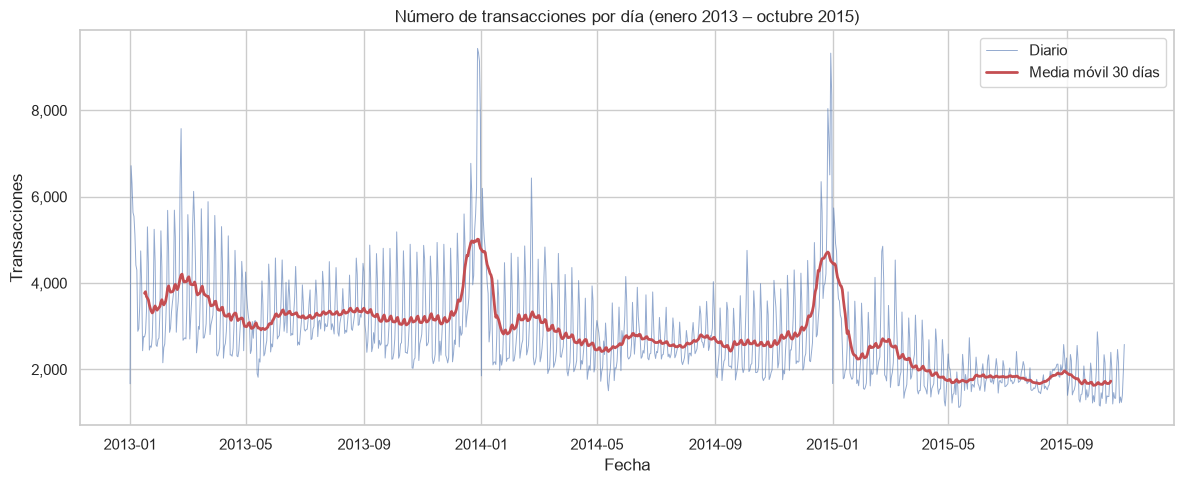

Métrica,Valor
Media diaria,"2,839"
Desviación estándar,"1,166"
Coeficiente de variación,41.1%
Mínimo,"1,123 (12/05/2015)"
Máximo,"9,434 (28/12/2013)"
Media diaria 2013,"3,473"
Media diaria 2014,"2,893"
Media diaria 2015,"2,015"
Día de la semana con más transacciones (media),"Sábado (3,989)"
Día de la semana con menos transacciones (media),"Lunes (2,293)"


In [13]:
daily_transactions = sales_train.groupby("date").size()
rolling_30 = daily_transactions.rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_transactions.index, daily_transactions, linewidth=0.7, alpha=0.6, label="Diario")
ax.plot(rolling_30.index, rolling_30, linewidth=2, color="C3", label="Media móvil 30 días")
ax.set_title("Número de transacciones por día (enero 2013 – octubre 2015)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Transacciones")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

DAY_NAMES = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
by_weekday = daily_transactions.groupby(daily_transactions.index.day_of_week).mean()
by_year = daily_transactions.groupby(daily_transactions.index.year).mean()

daily_summary = pd.DataFrame(
    {
        "Métrica": [
            "Media diaria",
            "Desviación estándar",
            "Coeficiente de variación",
            "Mínimo",
            "Máximo",
            *[f"Media diaria {year}" for year in by_year.index],
            "Día de la semana con más transacciones (media)",
            "Día de la semana con menos transacciones (media)",
        ],
        "Valor": [
            f"{daily_transactions.mean():,.0f}",
            f"{daily_transactions.std():,.0f}",
            f"{daily_transactions.std() / daily_transactions.mean():.1%}",
            f"{daily_transactions.min():,} ({daily_transactions.idxmin():%d/%m/%Y})",
            f"{daily_transactions.max():,} ({daily_transactions.idxmax():%d/%m/%Y})",
            *[f"{value:,.0f}" for value in by_year],
            f"{DAY_NAMES[by_weekday.idxmax()]} ({by_weekday.max():,.0f})",
            f"{DAY_NAMES[by_weekday.idxmin()]} ({by_weekday.min():,.0f})",
        ],
    }
)

style_table(daily_summary)

**Interpretación**

- La serie diaria es muy ruidosa: la media es de 2,839 transacciones por día con una desviación de 1,166
  (coeficiente de variación del 41.1 %), y va de 1,123 (12/05/2015) a 9,434 (28/12/2013).
- Hay un ciclo semanal marcado: el sábado promedia 3,989 transacciones frente a 2,293 del lunes. Es la
  oscilación de alta frecuencia que se ve en la línea diaria.
- Los picos más altos se concentran a finales de diciembre de cada año, lo que indica una fuerte
  estacionalidad anual por las compras de fin de año.
- La media móvil muestra una tendencia descendente: la media diaria baja de 3,473 en 2013 a 2,893 en 2014
  y a 2,015 en 2015.

#### Conclusión: frecuencia de agregación

Conviene trabajar con **frecuencia mensual** (`date_block_num`):

- **El objetivo es mensual.** `item_cnt_month` y `test.csv` se definen por mes y par tienda-producto, así
  que el modelo debe aprender y predecir a esa escala.
- **Reduce el ruido.** La serie diaria tiene un coeficiente de variación del 41.1 % y un ciclo semanal
  marcado. Al sumar por mes, ese ruido y el efecto del día de la semana se compensan.
- **Los meses son comparables.** Los 34 bloques están completos y `date_block_num` coincide con la fecha en
  todos los registros, así que la agregación mensual no introduce sesgos por días faltantes.
- **Conserva la señal útil.** La tendencia descendente y la estacionalidad de diciembre siguen siendo
  visibles a nivel mensual.

La frecuencia semanal no aporta ventajas: las semanas no encajan con los meses, que es la unidad del
pronóstico, y la serie seguiría siendo más ruidosa. La información diaria puede aprovecharse después como
variables derivadas (por ejemplo, número de días con ventas en el mes), pero el conjunto de modelado debe
construirse a nivel mensual.